# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: __________________________    Group: __________    Date: __________

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", "{:,.2f}".format)

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [49]:
# Set random seed
np.random.seed(42)

# Generate years of experience
years = np.random.randint(2, 21, size=500)

# Define intercept and slope
intercept = 60000
slope = (200000 - 60000) / (20 - 2)

# Generate noise
noise = np.random.normal(0, 10000, size=500)

# Calculate salary
salary = intercept + slope * years + noise

# Create DataFrame
df = pd.DataFrame({
    "YearsOfExperience": years,
    "Salary": salary
})

# Display first five rows
print(df.head())

# Check dataset shape
print("Dataset shape:", df.shape)

   YearsOfExperience     Salary
0                  8 115,037.78
1                 16 182,309.97
2                 12 156,442.41
3                  9 144,753.56
4                  8 130,798.82
Dataset shape: (500, 2)


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [50]:
# Display dataset shape
print("Dataset Shape:")
print(df.shape)

# Display summary statistics
print("\nSummary Statistics:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Calculate correlation
correlation = df["YearsOfExperience"].corr(df["Salary"])

print("\nCorrelation:")
print(correlation)

Dataset Shape:
(500, 2)

Summary Statistics:
       YearsOfExperience     Salary
count             500.00     500.00
mean               10.62 142,570.01
std                 5.66  44,935.26
min                 2.00  54,881.13
25%                 5.75 104,426.30
50%                10.00 139,865.03
75%                16.00 182,341.13
max                20.00 241,879.38

Missing Values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation:
0.975058457607618


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

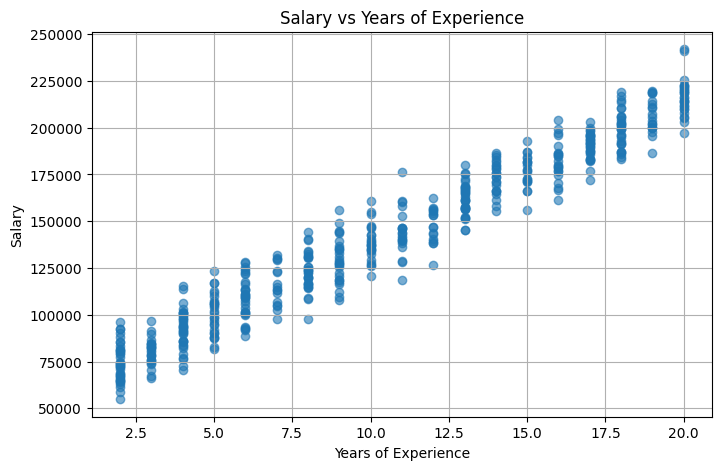

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["YearsOfExperience"],
    df["Salary"],
    alpha=0.6
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")

plt.grid(True)
plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [52]:
# Define X and y
X = df[["YearsOfExperience"]]
y = df["Salary"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display number of records
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [53]:
# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Calculate R2 scores
train_r2 = linear_model.score(X_train, y_train)
test_r2 = linear_model.score(X_test, y_test)

# Display results
print("Slope:", linear_model.coef_[0])
print("Intercept:", linear_model.intercept_)
print("Training R2:", train_r2)
print("Test R2:", test_r2)

Slope: 7696.612923052044
Intercept: 60961.340880280564
Training R2: 0.9488372177019488
Test R2: 0.9573704756930141


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [54]:
# Predict salaries
y_pred = linear_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display metrics
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

# Compare actual and predicted salaries
comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

display(comparison.head())

MAE: 7905.114728709239
MSE: 93933277.37947103
RMSE: 9691.918147584152
R2: 0.9573704756930141


,Actual Salary,Predicted Salary
0,"123,631.23","107,141.02"
1,"139,775.63","122,534.24"
2,"93,184.81","107,141.02"
3,"166,740.80","161,017.31"
4,"174,587.18","184,107.15"


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [55]:
# Calculate training mean
mean_salary = y_train.mean()

# Predict the same mean for every test record
baseline_pred = np.full(len(y_test), mean_salary)

# Calculate baseline metrics
baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

# Display comparison
baseline_comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse]
})

display(baseline_comparison)

,Model,MAE,RMSE
0,Mean Baseline,"40,444.96","46,953.77"
1,Linear Regression,"7,905.11","9,691.92"


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

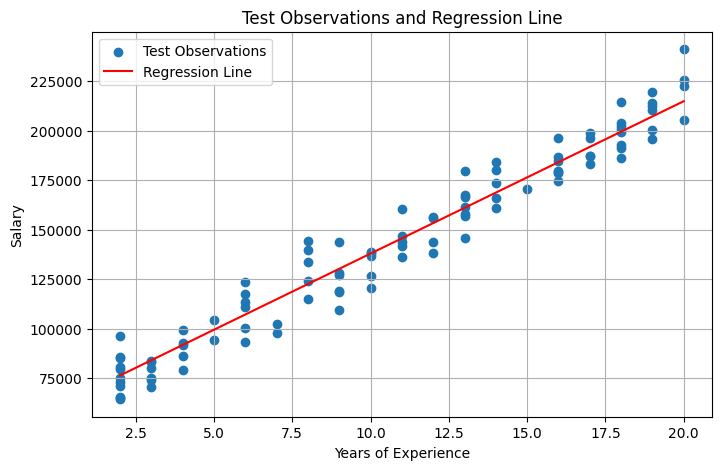

In [56]:
# Sort test data by experience
test_plot = pd.DataFrame({
    "Experience": X_test["YearsOfExperience"].values,
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
}).sort_values("Experience")

plt.figure(figsize=(8, 5))

plt.scatter(
    test_plot["Experience"],
    test_plot["Actual Salary"],
    label="Test Observations"
)

plt.plot(
    test_plot["Experience"],
    test_plot["Predicted Salary"],
    color="red",
    label="Regression Line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Test Observations and Regression Line")
plt.legend()
plt.grid(True)

plt.show()

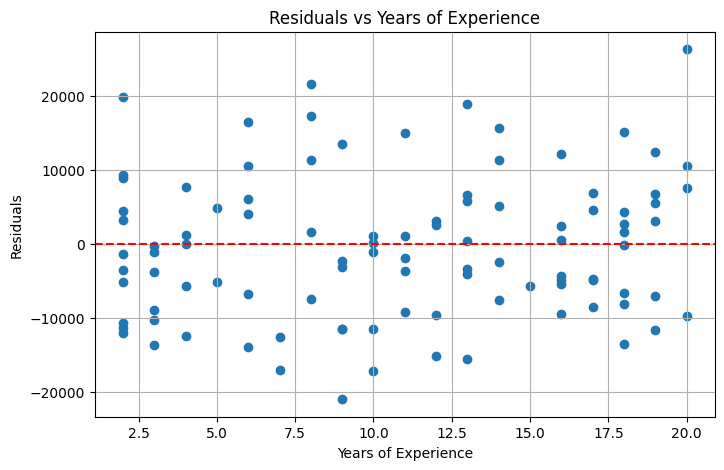

In [57]:
# Calculate residuals
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["YearsOfExperience"],
    residuals
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Years of Experience")
plt.ylabel("Residuals")
plt.title("Residuals vs Years of Experience")

plt.grid(True)
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [58]:
# Create new data
new_data = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15]
})

# Predict salaries
new_predictions = linear_model.predict(new_data)

# Create results table
prediction_table = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15],
    "Predicted Salary": new_predictions
})

display(prediction_table)

,YearsOfExperience,Predicted Salary
0,5,"99,444.41"
1,10,"137,927.47"
2,15,"176,410.53"


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [59]:
# Create StandardScaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data
X_test_scaled = scaler.transform(X_test)

print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (400, 1)
Testing scaled shape: (100, 1)


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [60]:
# Ridge with alpha = 10
ridge_10 = Ridge(alpha=10)
ridge_10.fit(X_train_scaled, y_train)

ridge_10_pred = ridge_10.predict(X_test_scaled)

ridge_10_mae = mean_absolute_error(y_test, ridge_10_pred)
ridge_10_r2 = r2_score(y_test, ridge_10_pred)


# Ridge with alpha = 100
ridge_100 = Ridge(alpha=100)
ridge_100.fit(X_train_scaled, y_train)

ridge_100_pred = ridge_100.predict(X_test_scaled)

ridge_100_mae = mean_absolute_error(y_test, ridge_100_pred)
ridge_100_r2 = r2_score(y_test, ridge_100_pred)


# Display results
ridge_results = pd.DataFrame({
    "Alpha": [10, 100],
    "Coefficient": [
        ridge_10.coef_[0],
        ridge_100.coef_[0]
    ],
    "Test MAE": [
        ridge_10_mae,
        ridge_100_mae
    ],
    "Test R2": [
        ridge_10_r2,
        ridge_100_r2
    ]
})

display(ridge_results)

,Alpha,Coefficient,Test MAE,Test R2
0,10,"42,156.50","8,084.46",0.96
1,100,"34,568.33","11,308.37",0.91


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [61]:
# Ridge with alpha = 10
ridge_10 = Ridge(alpha=10)
ridge_10.fit(X_train_scaled, y_train)

ridge_10_pred = ridge_10.predict(X_test_scaled)

ridge_10_mae = mean_absolute_error(y_test, ridge_10_pred)
ridge_10_r2 = r2_score(y_test, ridge_10_pred)


# Ridge with alpha = 100
ridge_100 = Ridge(alpha=100)
ridge_100.fit(X_train_scaled, y_train)

ridge_100_pred = ridge_100.predict(X_test_scaled)

ridge_100_mae = mean_absolute_error(y_test, ridge_100_pred)
ridge_100_r2 = r2_score(y_test, ridge_100_pred)


# Display results
ridge_results = pd.DataFrame({
    "Alpha": [10, 100],
    "Coefficient": [
        ridge_10.coef_[0],
        ridge_100.coef_[0]
    ],
    "Test MAE": [
        ridge_10_mae,
        ridge_100_mae
    ],
    "Test R2": [
        ridge_10_r2,
        ridge_100_r2
    ]
})

display(ridge_results)

,Alpha,Coefficient,Test MAE,Test R2
0,10,"42,156.50","8,084.46",0.96
1,100,"34,568.33","11,308.37",0.91


In [62]:
# Create and train Lasso model
lasso_1000 = Lasso(alpha=1000, max_iter=20000)

lasso_1000.fit(X_train_scaled, y_train)

print("Lasso model trained successfully!")

Lasso model trained successfully!


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [63]:
# Make predictions using selected models
ridge_pred = ridge_10.predict(X_test_scaled)

lasso_pred = lasso_1000.predict(X_test_scaled)


# Create final comparison table
final_results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Ridge (alpha=10)",
        "Lasso (alpha=1000)"
    ],

    "Test MAE": [
        baseline_mae,
        mae,
        mean_absolute_error(y_test, ridge_pred),
        mean_absolute_error(y_test, lasso_pred)
    ],

    "Test RMSE": [
        baseline_rmse,
        rmse,
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ],

    "Test R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ]
})

display(final_results)

,Model,Test MAE,Test RMSE,Test R2
0,Mean Baseline,"40,444.96","46,953.77",-0.00
1,Linear Regression,"7,905.11","9,691.92",0.96
2,Ridge (alpha=10),"8,084.46","9,876.93",0.96
3,Lasso (alpha=1000),"8,074.65","9,864.61",0.96


In [64]:
best_model = final_results.loc[
    final_results["Test MAE"].idxmin(), "Model"
]

print(
    f"{best_model} achieved the lowest test MAE, "
    "which means it had the smallest average prediction error."
)

print(
    "The regression models use years of experience to predict salary, "
    "while the mean baseline predicts the same salary for everyone."
)

Linear Regression achieved the lowest test MAE, which means it had the smallest average prediction error.
The regression models use years of experience to predict salary, while the mean baseline predicts the same salary for everyone.


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.